# DiffusionCB — Step 5: discriminability analysis

Reads the labelled CB runs from `data/*.parquet` and asks the paper's core question:
**does the raw (un-averaged) data separate the 3 noise classes where the standard
CB number λ_P cannot?**

Fingerprints, in order: **5a** averaged view `F_{P,m}` + λ_P (the baseline) ·
**5b** spread across sequences `Var_l(f)` · **5c** cross-Pauli structure · **5d** verdict.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
# load all labelled runs into one long-format dataframe
DATA_DIR = Path("data")
files  = sorted(DATA_DIR.glob("*.parquet"))
df_all = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print(f"loaded {len(files)} files, {len(df_all)} rows")
df_all.head()

loaded 24 files, 12960 rows


,noisetype,param,param_value,seed,P,m,l,f_pml,n_plus,n_minus,pauli_sign,twirl_seq
0,drift,eps,0.05,0,X,2,0,1.0,0,1024,-1,"[Z, Y, Y]"
1,drift,eps,0.05,0,X,2,1,1.0,1024,0,1,"[X, X, I]"
2,drift,eps,0.05,0,X,2,2,1.0,1024,0,1,"[I, I, I]"
3,drift,eps,0.05,0,X,2,3,1.0,0,1024,-1,"[Z, Y, Z]"
4,drift,eps,0.05,0,X,2,4,1.0,0,1024,-1,"[Y, Y, Z]"


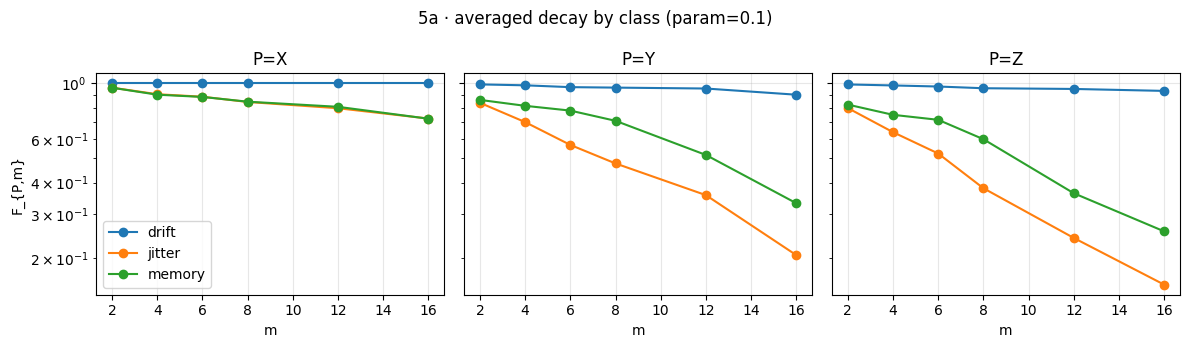

In [5]:
# 5a — averaged view F_{P,m}  (the baseline: exactly what standard CB sees)
F = (df_all.groupby(["noisetype", "param_value", "P", "m"])["f_pml"]
            .mean().reset_index(name="F"))

pval   = 0.10                              # compare the 3 classes at one dial setting
paulis = sorted(F.P.unique())
fig, axes = plt.subplots(1, len(paulis), figsize=(4*len(paulis), 3.5), sharey=True)
for ax, P in zip(axes, paulis):
    for cls, g in F[(F.P == P) & (F.param_value == pval)].groupby("noisetype"):
        g = g.sort_values("m")
        ax.plot(g.m, g.F, "o-", label=cls)
    ax.set_yscale("log"); ax.set_title(f"P={P}"); ax.set_xlabel("m"); ax.grid(alpha=.3)
axes[0].set_ylabel("F_{P,m}"); axes[0].legend()
fig.suptitle(f"5a · averaged decay by class (param={pval})")
plt.tight_layout(); plt.show()


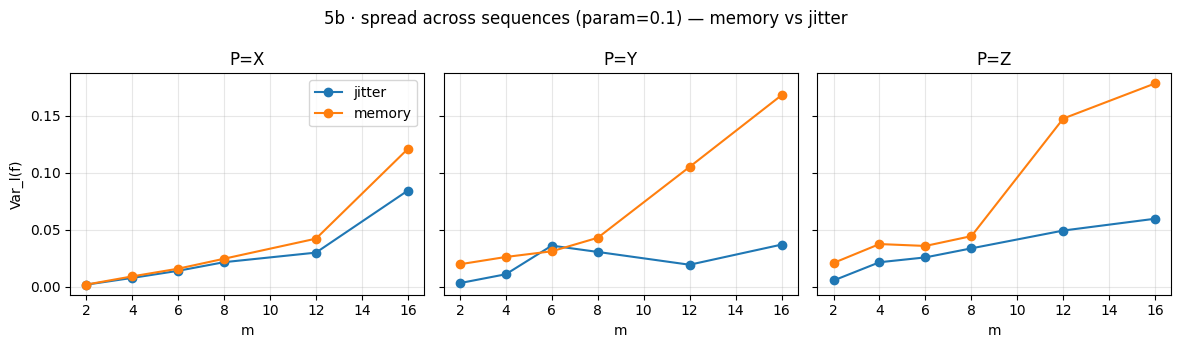

In [6]:
# 5b — variances view F_{P,m}  (the baseline: exactly what standard CB sees)
var_F = (df_all.groupby(["noisetype", "param_value", "P", "m"])["f_pml"]
            .var().reset_index(name="var"))

# 5b plot — spread Var_l(f) vs m, memory vs jitter at matched λ (param=0.10)
pval    = 0.10
compare = ["memory", "jitter"]                 # the matched-λ pair (drift not matched yet)
paulis  = sorted(var_F.P.unique())
fig, axes = plt.subplots(1, len(paulis), figsize=(4*len(paulis), 3.5), sharey=True)
for ax, P in zip(axes, paulis):
    sub = var_F[(var_F.P == P) & (var_F.param_value == pval)
                & (var_F.noisetype.isin(compare))]
    for cls, g in sub.groupby("noisetype"):
        g = g.sort_values("m")
        ax.plot(g.m, g["var"], "o-", label=cls)
    ax.set_title(f"P={P}"); ax.set_xlabel("m"); ax.grid(alpha=.3)
axes[0].set_ylabel("Var_l(f)"); axes[0].legend()
fig.suptitle(f"5b · spread across sequences (param={pval}) — memory vs jitter")
plt.tight_layout(); plt.show()

